# LankaGrid AI: Ensemble Learning Experiments

**Sri Lankan daily electricity-generation forecasting dashboard**

**Objective:** Compare baseline and ensemble regression models for one-day-ahead forecasting of daily electricity generation in GWh. The project uses a chronological 80/20 train-test split and compares bagging, boosting, stacking, and fixed-weight hybrids.

**Important:** Generation is used as a measurable supply proxy; it is not necessarily identical to end-use electricity demand.

**Dataset:** `data/electricity.csv`  
**Columns:** `date` (daily observation date) and `total_gwh` (daily generation in GWh)

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from train import load_data, features, FEATURES, build_models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_ROOT = Path.cwd()
CSV_PATH = PROJECT_ROOT / 'data' / 'electricity.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'Project: {PROJECT_ROOT}')
print(f'Dataset:  {CSV_PATH}')

Project: C:\Users\Vinod Madhawa\Desktop\ML Assignment 1\LankaGrid_AI
Dataset:  C:\Users\Vinod Madhawa\Desktop\ML Assignment 1\LankaGrid_AI\data\electricity.csv


## 1. Data loading and validation

The data loader verifies required columns, parses dates and numeric values, removes unusable rows, sorts observations chronologically, checks duplicate dates and missing calendar days, rejects nonpositive generation values, and requires at least 150 observations.

In [2]:
raw = load_data(str(CSV_PATH), date_col='date', target_col='total_gwh')

print('Observations:', len(raw))
print('Date range:', raw.index.min().date(), 'to', raw.index.max().date())
print('Minimum daily generation:', round(raw['energy_gwh'].min(), 2), 'GWh')
print('Maximum daily generation:', round(raw['energy_gwh'].max(), 2), 'GWh')
print('Mean daily generation:', round(raw['energy_gwh'].mean(), 2), 'GWh')

display(raw.head())
display(raw.tail())

Observations: 3340
Date range: 2017-01-01 to 2026-02-22
Minimum daily generation: 24.95 GWh
Maximum daily generation: 90.41 GWh
Mean daily generation: 42.4 GWh


,energy_gwh
date,
2017-01-01,30.83
2017-01-02,36.45
2017-01-03,39.24
2017-01-04,38.84
2017-01-05,38.23


,energy_gwh
date,
2026-02-18,59.44
2026-02-19,60.60
2026-02-20,61.07
2026-02-21,57.35
2026-02-22,52.72


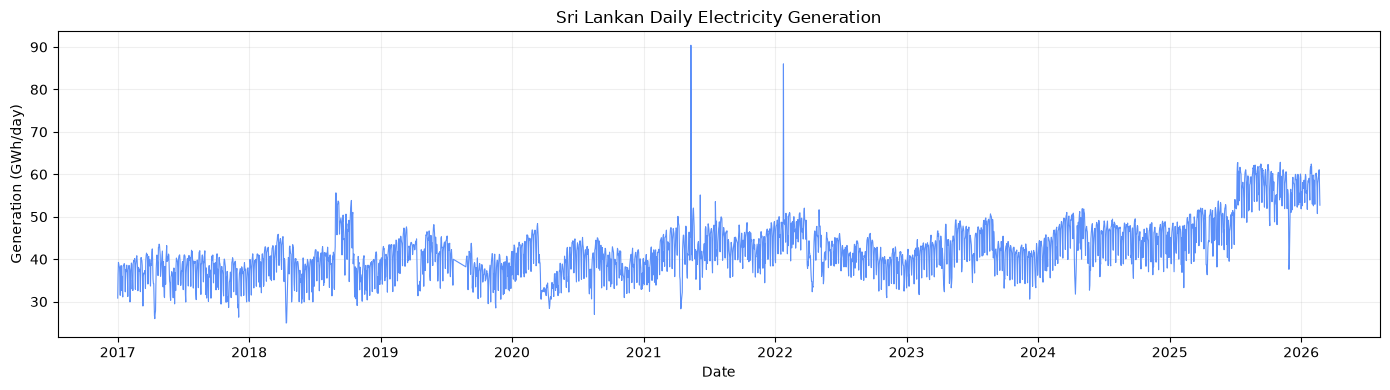

Missing values: 0
Duplicate dates: 0


In [3]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(raw.index, raw['energy_gwh'], color='#5B8FF9', linewidth=0.8)
ax.set(title='Sri Lankan Daily Electricity Generation', xlabel='Date', ylabel='Generation (GWh/day)')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print('Missing values:', int(raw.isna().sum().sum()))
print('Duplicate dates:', int(raw.index.duplicated().sum()))

## 2. Feature engineering and chronological split

The target is the current day's generation. Predictors are earlier lag values, shifted rolling means and rolling standard deviation, and calendar features. A chronological 80/20 split prevents future observations from training the models.

The hybrid models are fixed 50/50 weighted averages of saved component predictions. Their weights are not tuned on the held-out test set.

In [4]:
df = features(raw['energy_gwh'])
cut = int(len(df) * 0.80)
train_df = df.iloc[:cut]
test_df = df.iloc[cut:]

X_train = train_df[FEATURES]
y_train = train_df['energy_gwh']
X_test = test_df[FEATURES]
y_test = test_df['energy_gwh']

print('Engineered observations:', len(df))
print('Training rows:', len(train_df), '|', train_df.index.min().date(), 'to', train_df.index.max().date())
print('Test rows:', len(test_df), '|', test_df.index.min().date(), 'to', test_df.index.max().date())
print('Features:', FEATURES)

Engineered observations: 3312
Training rows: 2649 | 2017-01-29 to 2024-04-30
Test rows: 663 | 2024-05-01 to 2026-02-22
Features: ['lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'mean_7', 'mean_14', 'std_7', 'dayofweek', 'month', 'dayofyear', 'weekend']


## 3. Ensemble model setup

The experiment includes a Decision Tree baseline, bagging, Random Forest, AdaBoost, Gradient Boosting, Histogram Gradient Boosting, XGBoost, StackingRegressor, and two fixed-weight hybrid forecasts.

In [5]:
models = build_models()
for name, model in models.items():
    print(f'{name}: {type(model).__name__}')

Decision Tree: DecisionTreeRegressor
Bagging: BaggingRegressor
Random Forest: RandomForestRegressor
Gradient Boosting: GradientBoostingRegressor
Histogram Boosting: HistGradientBoostingRegressor
AdaBoost: AdaBoostRegressor
XGBoost: XGBRegressor
Stacking: StackingRegressor


## 4. Training, prediction, and held-out evaluation

Only the training partition is used to fit each model. MAE and RMSE are reported in GWh/day; R-squared indicates the proportion of test variability explained by the model.

In [6]:
predictions = {}
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    trained_models[name] = model

predictions['Hybrid RF + GB'] = 0.5 * predictions['Random Forest'] + 0.5 * predictions['Gradient Boosting']
predictions['Hybrid XGB + GB'] = 0.5 * predictions['XGBoost'] + 0.5 * predictions['Gradient Boosting']

rows = []
for name, pred in predictions.items():
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
display(results.style.format({'MAE': '{:.3f}', 'RMSE': '{:.3f}', 'R2': '{:.4f}'}))

best_model = results.iloc[0]['Model']
print('Lowest-MAE model:', best_model)

,Model,MAE,RMSE,R2
0,Random Forest,3.796,5.160,0.4081
1,Bagging,3.825,5.203,0.3982
2,Hybrid RF + GB,3.897,5.325,0.3699
3,Stacking,3.908,5.451,0.3397
4,Gradient Boosting,4.037,5.551,0.3152
5,Hybrid XGB + GB,4.140,5.667,0.2863
6,XGBoost,4.269,5.827,0.2454
7,Decision Tree,4.470,6.088,0.1763
8,Histogram Boosting,4.848,6.762,-0.0162
9,AdaBoost,5.122,6.705,0.0009


Lowest-MAE model: Random Forest


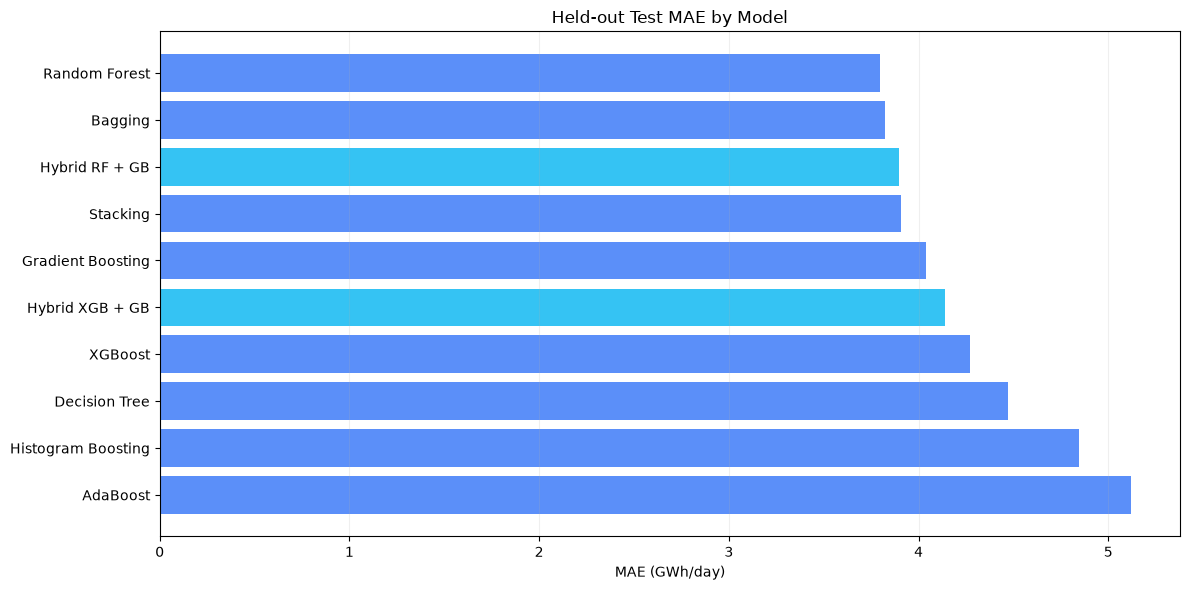

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#35C3F3' if 'Hybrid' in model else '#5B8FF9' for model in results['Model']]
ax.barh(results['Model'], results['MAE'], color=colors)
ax.invert_yaxis()
ax.set(title='Held-out Test MAE by Model', xlabel='MAE (GWh/day)', ylabel='')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

In [8]:
comparison = pd.DataFrame({'Date': test_df.index, 'Actual': y_test.values})
for name, pred in predictions.items():
    comparison[name] = pred

comparison.to_csv(OUTPUT_DIR / 'predictions.csv', index=False)
results.rename(columns={'Model': 'model'}).to_csv(OUTPUT_DIR / 'metrics.csv', index=False)

print('Saved:', OUTPUT_DIR / 'metrics.csv')
print('Saved:', OUTPUT_DIR / 'predictions.csv')
display(comparison.head())

Saved: C:\Users\Vinod Madhawa\Desktop\ML Assignment 1\LankaGrid_AI\outputs\metrics.csv
Saved: C:\Users\Vinod Madhawa\Desktop\ML Assignment 1\LankaGrid_AI\outputs\predictions.csv


,Date,Actual,Decision Tree,Bagging,Random Forest,Gradient Boosting,Histogram Boosting,AdaBoost,XGBoost,Stacking,Hybrid RF + GB,Hybrid XGB + GB
0,2024-05-01,40.01,47.704612,47.855539,47.864015,47.865889,47.507351,46.975095,48.024349,48.450095,47.864952,47.945119
1,2024-05-02,50.08,41.137500,43.424120,43.148439,43.465116,42.867077,43.444772,41.848793,43.619859,43.306778,42.656955
2,2024-05-03,51.90,49.246601,48.228780,48.102567,48.523302,47.496290,47.391275,46.391247,49.000391,48.312935,47.457274
3,2024-05-04,49.66,47.943419,47.694067,47.835891,48.803277,48.139444,46.711802,48.093674,49.269410,48.319584,48.448475
4,2024-05-05,44.81,47.594653,46.066544,46.118752,44.905713,44.947537,45.681215,45.435127,45.937844,45.512232,45.170420


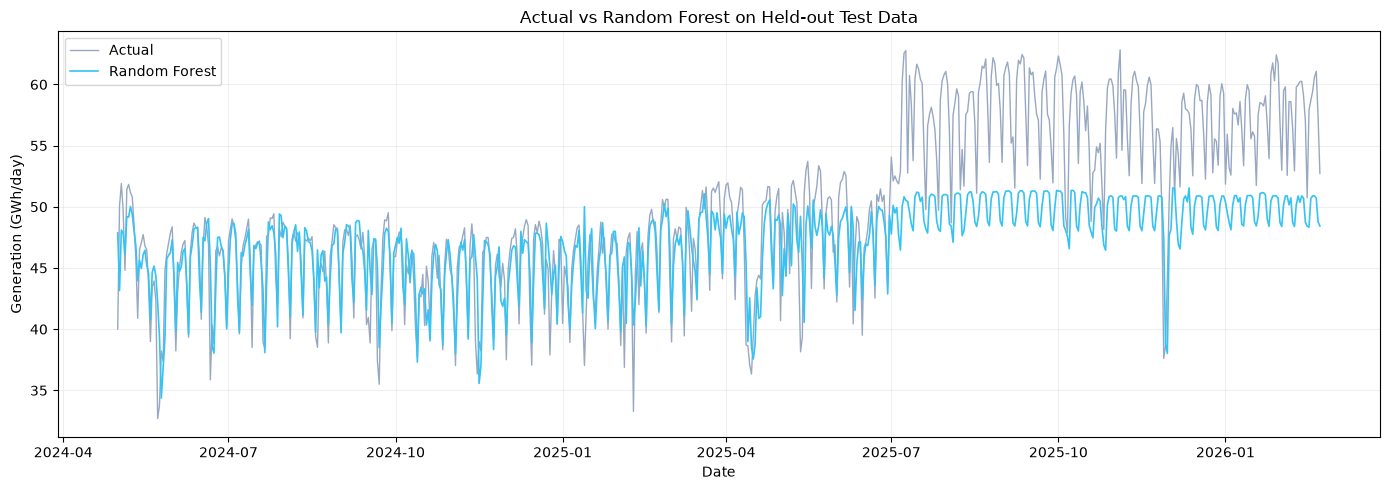

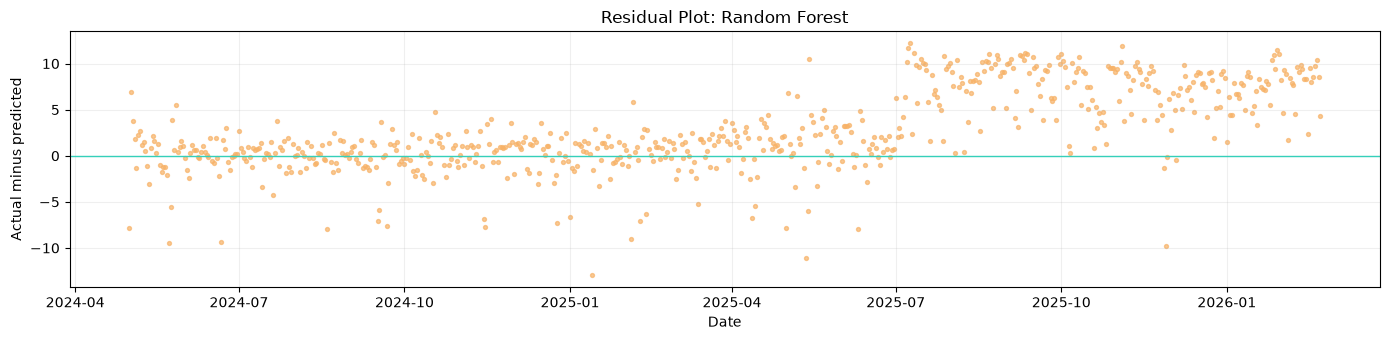

In [9]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(comparison['Date'], comparison['Actual'], label='Actual', color='#98A8C2', linewidth=1)
ax.plot(comparison['Date'], comparison[best_model], label=best_model, color='#35C3F3', linewidth=1.2)
ax.set(title=f'Actual vs {best_model} on Held-out Test Data', xlabel='Date', ylabel='Generation (GWh/day)')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

residuals = comparison['Actual'] - comparison[best_model]
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.scatter(comparison['Date'], residuals, s=8, color='#F7B267', alpha=0.7)
ax.axhline(0, color='#35D0BA', linewidth=1)
ax.set(title=f'Residual Plot: {best_model}', xlabel='Date', ylabel='Actual minus predicted')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 5. Interpretation and limitations

- The lowest-MAE model is identified directly from the held-out chronological test results above.
- Ensemble methods should be compared against the simple Decision Tree baseline, not only against each other.
- Bagging mainly reduces variance, boosting sequentially reduces bias and error, Random Forest combines decorrelated trees, and Stacking learns a weighted combination through cross-validation.
- The fixed 50/50 hybrid values are demonstrations. They should not be described as optimized unless tuning is performed on a separate validation set.
- R-squared can be negative when a model performs worse than predicting the test mean.
- Lag and rolling features make the task one-day-ahead forecasting rather than arbitrary-date forecasting.
- The result is evidence for this dataset and time split only. Rolling-origin validation would provide a stronger estimate of generalization performance.
- No data source, extraction date, or source URL is fabricated. The project README should record the actual source and verification status before external submission.